In [1]:
# 📦 Imports
import pyodbc
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# 🔗 Connexion SQL Server
conn_str = (
    "Driver={ODBC Driver 17 for SQL Server};"
    "Server=LAPTOP-GPVK1ANC;"
    "Database=DW_SupplyChain;"
    "Trusted_Connection=yes;"
)
cnxn = pyodbc.connect(conn_str)

In [3]:
# 📥 Extraction des données
query = """
SELECT 
    productFK,
    brandFK,
    Production_Start_Time,
    Production_End_Time,
    manufacturedate,
    expirydate,
    Dosage,
    quantityused
FROM fact_production
"""
df = pd.read_sql(query, cnxn)


C:\Users\ayadi\AppData\Local\Temp\ipykernel_2148\1892364536.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnxn)


In [4]:
# 🧹 Prétraitement des dates
df['Production_Start_Time'] = pd.to_datetime(df['Production_Start_Time'], errors='coerce')
df['Production_End_Time'] = pd.to_datetime(df['Production_End_Time'], errors='coerce')


In [5]:
# Calcul de la durée de production (en minutes)
df['Production_Duration_Minutes'] = (df['Production_End_Time'] - df['Production_Start_Time']).dt.total_seconds() / 60


In [6]:
# Filtrage des colonnes utiles
df_cluster = df[['Production_Duration_Minutes', 'Dosage', 'quantityused']].copy()


In [ ]:

# Conversion correcte de 'quantityused'
df_cluster['quantityused'] = pd.to_numeric(df_cluster['quantityused'], errors='coerce')

In [ ]:

df_cluster = df_cluster.dropna()
df_cluster = df_cluster[df_cluster['Production_Duration_Minutes'] > 0]
df_cluster = df_cluster[df_cluster['quantityused'] < df_cluster['quantityused'].quantile(0.99)]


In [9]:
# 🔢 Standardisation
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_cluster[['Production_Duration_Minutes', 'Dosage', 'quantityused']])


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak

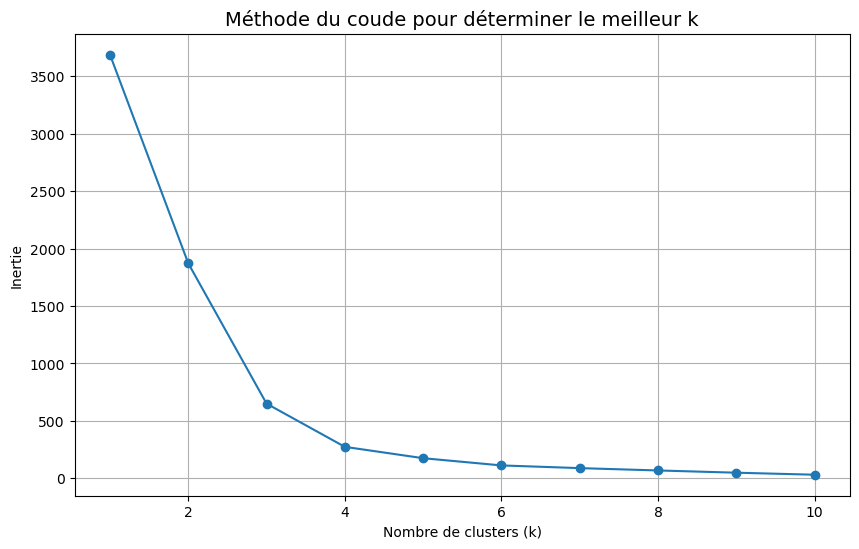

In [10]:
# 📉 Méthode du coude
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia, marker='o')
plt.title("Méthode du coude pour déterminer le meilleur k", fontsize=14)
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie")
plt.grid(True)
plt.show()


In [11]:
# 🔁 Clustering avec k=3 
k_optimal = 3
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
clusters = kmeans.fit_predict(df_scaled)

# Attribution des clusters
df_cluster['Cluster'] = clusters

C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


In [12]:
# 🏷️ Attribution des noms professionnels
cluster_names = {
    0: "Production Légère & Rapide",
    1: "Production Intensive",
    2: "Production Anormale / Rare"
}
df_cluster['Cluster_Label'] = df_cluster['Cluster'].map(cluster_names)

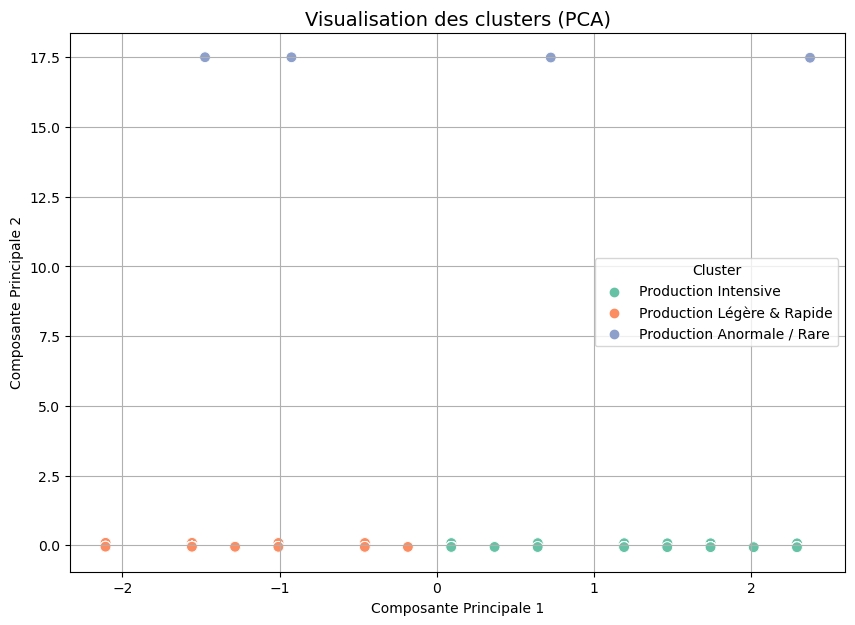

In [13]:
# 📊 PCA pour visualisation
pca = PCA(n_components=2)
components = pca.fit_transform(df_scaled)
df_cluster['PCA1'] = components[:, 0]
df_cluster['PCA2'] = components[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PCA1', y='PCA2',
    hue='Cluster_Label',
    palette='Set2',
    data=df_cluster,
    s=60
)
plt.title("Visualisation des clusters (PCA)", fontsize=14)
plt.xlabel("Composante Principale 1")
plt.ylabel("Composante Principale 2")
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

In [14]:
# 📋 Résumé des clusters
summary = df_cluster.groupby('Cluster').agg({
    'Production_Duration_Minutes': ['mean', 'min', 'max'],
    'Dosage': ['mean', 'min', 'max'],
    'quantityused': ['mean', 'min', 'max'],
    'Cluster': 'count'
})
summary.columns = ['_'.join(col).strip() for col in summary.columns.values]
summary.rename(columns={'Cluster_count': 'Count'}, inplace=True)

print("📊 Résumé des clusters :")
print(summary)

📊 Résumé des clusters :
         Production_Duration_Minutes_mean  Production_Duration_Minutes_min  \
Cluster                                                                      
0                            4.685632e-09                     1.283333e-09   
1                            3.805297e-09                     1.283333e-09   
2                            1.478295e-05                     1.478295e-05   

         Production_Duration_Minutes_max  Dosage_mean  Dosage_min  Dosage_max  \
Cluster                                                                         
0                           1.212833e-07     2.525862           1           8   
1                           1.212833e-07     6.936434           2          10   
2                           1.478295e-05     5.000000           2           9   

         quantityused_mean  quantityused_min  quantityused_max  Count  
Cluster                                                                
0                 2.477586         